# **Load & Clean**

In [ ]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, r2_score

# 1. Load
cols = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
        'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
        'hours-per-week', 'native-country', 'income']
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
df = pd.read_csv(url, names=cols, na_values="?", skipinitialspace=True).dropna()

# 2. Encode target
df['income'] = df['income'].apply(lambda x: 1 if x == '>50K' else 0)

# 3. Prepare X and y (Drop fnlwgt, education, AND education-num so it matches frontend!)
X = df.drop(['income', 'fnlwgt', 'education', 'education-num'], axis=1)
y = df['income']
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
print("Data ready! Encoded features:", X_encoded.shape[1])

Data ready! Encoded features: 79


# Train Logistic Regression (Classification)

In [ ]:
import warnings
warnings.filterwarnings('ignore')

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

log_preds = log_model.predict(X_test)
log_acc = accuracy_score(y_test, log_preds)
print(f"Logistic Regression Accuracy: {log_acc*100:.2f}%")

Logistic Regression Accuracy: 84.15%


# **Train Decision Tree (Classification)**

In [ ]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
tree_acc = accuracy_score(y_test, tree_model.predict(X_test))
print(f"Decision Tree Accuracy: {tree_acc*100:.2f}%")

Decision Tree Accuracy: 81.67%


# **Save the 4 Files**

In [ ]:
joblib.dump(log_model, 'census_logistic_model.pkl')
joblib.dump(list(X_encoded.columns), 'census_logistic_columns.pkl')
joblib.dump(tree_model, 'census_tree_model.pkl')
joblib.dump(list(X_encoded.columns), 'census_tree_columns.pkl')
print(" Saved all 4 files. .")

 Saved all 4 files. .


# Detailed **Evaluation**


LOGISTIC REGRESSION
              precision    recall  f1-score   support

       <=50K       0.87      0.92      0.90      4503
        >50K       0.73      0.60      0.66      1530

    accuracy                           0.84      6033
   macro avg       0.80      0.76      0.78      6033
weighted avg       0.84      0.84      0.84      6033

DECISION TREE
              precision    recall  f1-score   support

       <=50K       0.87      0.89      0.88      4503
        >50K       0.65      0.60      0.63      1530

    accuracy                           0.82      6033
   macro avg       0.76      0.75      0.75      6033
weighted avg       0.81      0.82      0.81      6033


SUMMARY (>50K class ke liye):
              Model  Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression    0.8415     0.7253  0.6039 0.6591   0.8943
      Decision Tree    0.8167     0.6493  0.6026 0.6251   0.7914


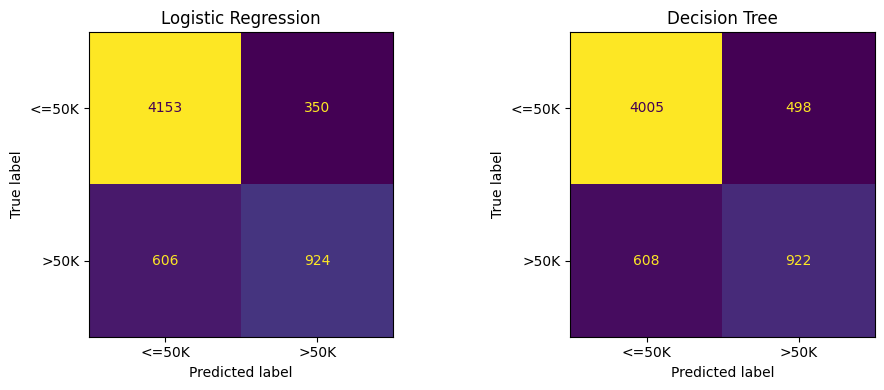


Baseline (hamesha '<=50K' bolna): 74.64% accuracy


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# Predictions aur probabilities
log_preds  = log_model.predict(X_test)
tree_preds = tree_model.predict(X_test)
log_proba  = log_model.predict_proba(X_test)[:, 1]
tree_proba = tree_model.predict_proba(X_test)[:, 1]

labels = ["<=50K", ">50K"]

# 1. Classification report (precision, recall, F1 har class ke liye)
print("=" * 55)
print("LOGISTIC REGRESSION")
print("=" * 55)
print(classification_report(y_test, log_preds, target_names=labels))

print("=" * 55)
print("DECISION TREE")
print("=" * 55)
print(classification_report(y_test, tree_preds, target_names=labels))

# 2. Summary table
summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy":  [accuracy_score(y_test, log_preds),  accuracy_score(y_test, tree_preds)],
    "Precision": [precision_score(y_test, log_preds), precision_score(y_test, tree_preds)],
    "Recall":    [recall_score(y_test, log_preds),    recall_score(y_test, tree_preds)],
    "F1":        [f1_score(y_test, log_preds),        f1_score(y_test, tree_preds)],
    "ROC-AUC":   [roc_auc_score(y_test, log_proba),   roc_auc_score(y_test, tree_proba)],
}).round(4)
print("\nSUMMARY (>50K class ke liye):")
print(summary.to_string(index=False))

# 3. Confusion matrices (side by side)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, preds, title in zip(axes, [log_preds, tree_preds],
                            ["Logistic Regression", "Decision Tree"]):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

# 4. Majority baseline
baseline = (y_test == 0).mean()
print(f"\nBaseline (hamesha '<=50K' bolna): {baseline*100:.2f}% accuracy")

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import joblib

SAVE = True

print("ORIGINAL TREE")
print(f"  Depth: {tree_model.get_depth()} | Leaves: {tree_model.get_n_leaves()}")
print(f"  Train accuracy: {tree_model.score(X_train, y_train):.4f}")
print(f"  Test accuracy : {tree_model.score(X_test, y_test):.4f}")

param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12],
    "min_samples_leaf": [5, 10, 20, 50, 100],
    "criterion": ["gini", "entropy"],
}
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid, cv=5, scoring="f1", n_jobs=-1
)
grid.fit(X_train, y_train)
best_tree = grid.best_estimator_
print("\nBest settings:", grid.best_params_)

print("\nTUNED TREE")
print(f"  Depth: {best_tree.get_depth()} | Leaves: {best_tree.get_n_leaves()}")
print(f"  Train accuracy: {best_tree.score(X_train, y_train):.4f}")
print(f"  Test accuracy : {best_tree.score(X_test, y_test):.4f}")

rows = []
for name, m in [("Logistic Regression", log_model),
                ("Tree (original)", tree_model),
                ("Tree (tuned)", best_tree)]:
    p = m.predict(X_test)
    rows.append([name, accuracy_score(y_test, p), precision_score(y_test, p),
                 recall_score(y_test, p), f1_score(y_test, p),
                 roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])])

print("\n", pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1","ROC-AUC"]).round(4).to_string(index=False))

if SAVE:
    joblib.dump(best_tree, "census_tree_model.pkl")
    print("\nSaved tuned tree as census_tree_model.pkl")

ORIGINAL TREE
  Depth: 50 | Leaves: 4442
  Train accuracy: 0.9540
  Test accuracy : 0.8167

Best settings: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 5}

TUNED TREE
  Depth: 12 | Leaves: 366
  Train accuracy: 0.8637
  Test accuracy : 0.8536

               Model  Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression    0.8415     0.7253  0.6039 0.6591   0.8943
    Tree (original)    0.8167     0.6493  0.6026 0.6251   0.7914
       Tree (tuned)    0.8536     0.7694  0.6039 0.6767   0.8889

Saved tuned tree as census_tree_model.pkl
